# Vision Transformer (ViT) for Unsupervised Industrial Anomaly Detection on MVTec AD

**Course:** Deep Learning for Visual Data (MAAI901) | **Dataset:** MVTec AD (all 15 categories, from Hugging Face)

## 1. Problem
In a factory, defective products are rare and come in unpredictable shapes. We cannot collect enough defect images to train a normal classifier.
So we use **unsupervised anomaly detection**: the model sees only **normal (defect-free)** images during training, and at test time it must
(a) say whether an image is normal or defective (**image-level**), and (b) show **where** the defect is (**pixel-level**, a heat map).

## 2. Our method (ViT + PatchCore-style memory bank)
1. Use a **pretrained Vision Transformer (DINO ViT-B/16)** as a frozen feature extractor. No training/fine-tuning is needed.
2. Cut every image into 16x16 patches; the ViT gives one feature vector per patch (with global context through self-attention).
3. For every category, collect patch features of all **normal training images** and keep a compact subset (**greedy coreset**) = the **memory bank**.
4. At test time, for each patch we find its **nearest neighbour distance** in the memory bank. Far from every normal patch = anomalous.
5. Patch distances -> anomaly heat map (pixel-level). The maximum of the map -> anomaly score of the image (image-level).
6. We compare the ViT with a **CNN baseline (WideResNet-50)** using the same pipeline, and run an **ablation** on which ViT layers to use.

**Metrics:** Image AUROC and Pixel AUROC (standard for MVTec AD).

## Step 0 - Install libraries
Set **Runtime > Change runtime type > T4 GPU** before running.

In [ ]:
!pip -q install -U transformers huggingface_hub scikit-learn scipy pandas matplotlib tqdm

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.3.0 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 2.3.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.


## Step 1 - Imports, settings (config) and reproducibility

In [ ]:
import os, glob, json, time, random, math
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score, roc_curve
from scipy.ndimage import gaussian_filter
from huggingface_hub import snapshot_download
from transformers import ViTModel
from torchvision.models import wide_resnet50_2, Wide_ResNet50_2_Weights

# ----------------------------- SETTINGS (change here only) -----------------------------
ALL_CATEGORIES = ["bottle", "cable", "capsule", "carpet", "grid", "hazelnut", "leather",
                  "metal_nut", "pill", "screw", "tile", "toothbrush", "transistor", "wood", "zipper"]

CATEGORIES = ALL_CATEGORIES        # TIP: first test with ["bottle"] (fast), then run all 15
IMG_SIZE = 224                     # input resolution (224 = native size of the ViT, gives a 14x14 patch grid)
BATCH_SIZE = 32                    # images per batch (reduce to 16 if GPU memory error)
CORESET_RATIO = 0.10               # keep 10% of normal patch features in the memory bank
GAUSS_SIGMA = 4                    # smoothing of the anomaly map (makes the heat map cleaner)

VIT_NAME = "facebook/dino-vitb16"  # self-supervised ViT-B/16 (good local/patch features)
VIT_LAYERS = [8, 11]               # which transformer blocks to take features from (1..12)
RUN_CNN_BASELINE = True            # also run WideResNet-50 baseline for comparison
SEED = 42

DATA_ROOT = "/content/mvtec_ad"    # where the dataset will be downloaded
OUT_DIR = "/content/outputs"       # results, memory banks, figures
# ---------------------------------------------------------------------------------------

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(f"{OUT_DIR}/banks", exist_ok=True)

# Fix random seeds so results are reproducible (important for a report)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "NO GPU! Enable it in Runtime settings")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Device: cuda | Tesla T4


## Step 2 - Download MVTec AD from Hugging Face
The repo keeps the original folder structure: `category/train/good`, `category/test/<defect_type>`, `category/ground_truth/<defect_type>`.

In [ ]:
# Download only the categories we need (all 15 = about 5 GB, takes a few minutes)
snapshot_download(
    repo_id="foersben/mvtec-ad",
    repo_type="dataset",
    local_dir=DATA_ROOT,
    allow_patterns=[f"{c}/*" for c in CATEGORIES],
    max_workers=8,
)
print("Downloaded to:", DATA_ROOT)
print(sorted(os.listdir(DATA_ROOT)))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6642 files:   0%|          | 0/6642 [00:00<?, ?it/s]

Downloaded to: /content/mvtec_ad
['.cache', 'bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper']


## Step 3 - Dataset class
Reads images and (for test defects) the ground-truth masks. Training split has only normal (`good`) images.

In [ ]:
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp"}

def list_images(folder):
    """Return sorted list of image files in a folder (empty list if the folder does not exist)."""
    folder = Path(folder)
    if not folder.exists():
        return []
    return sorted(p for p in folder.iterdir() if p.suffix.lower() in IMG_EXT)

# ImageNet mean/std: both our ViT and CNN were pretrained with this normalization
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


class MVTecDataset(Dataset):
    """One MVTec AD category. split = 'train' (only normal) or 'test' (normal + defective)."""

    def __init__(self, root, category, split, img_size=224):
        self.img_size = img_size
        self.samples = []                       # list of dicts: image path, mask path, label, defect type
        cat_dir = Path(root) / category

        if split == "train":
            for p in list_images(cat_dir / "train" / "good"):
                self.samples.append(dict(img=p, mask=None, label=0, type="good"))
        else:
            for d in sorted((cat_dir / "test").iterdir()):
                if not d.is_dir():
                    continue
                for p in list_images(d):
                    if d.name == "good":
                        self.samples.append(dict(img=p, mask=None, label=0, type="good"))
                    else:
                        # mask of "xxx.png" is stored as "xxx_mask.png"
                        m = cat_dir / "ground_truth" / d.name / (p.stem + "_mask.png")
                        self.samples.append(dict(img=p, mask=m, label=1, type=d.name))

    def __len__(self):
        return len(self.samples)

    def load_pil(self, path):
        """Open an image as RGB (some categories like grid/screw are grayscale) and resize."""
        return Image.open(path).convert("RGB").resize((self.img_size, self.img_size), Image.BICUBIC)

    def __getitem__(self, i):
        s = self.samples[i]
        img = self.load_pil(s["img"])
        x = torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1).float() / 255.0   # (3,H,W) in [0,1]
        x = (x - MEAN) / STD                                                              # normalize

        if s["mask"] is not None and Path(s["mask"]).exists():
            m = Image.open(s["mask"]).convert("L").resize((self.img_size, self.img_size), Image.NEAREST)
            m = (torch.from_numpy(np.asarray(m).copy()) > 0).float()                      # 1 = defect pixel
        else:
            m = torch.zeros(self.img_size, self.img_size)                                 # normal image: no defect
        return x, m, s["label"], str(s["img"]), s["type"]


def dataset_summary():
    """Table with number of images per category (useful for the 'Dataset' section of the report)."""
    rows = []
    for c in CATEGORIES:
        root = Path(DATA_ROOT) / c
        types = [d.name for d in (root / "test").iterdir() if d.is_dir() and d.name != "good"]
        rows.append(dict(category=c,
                         train_normal=len(list_images(root / "train" / "good")),
                         test_normal=len(list_images(root / "test" / "good")),
                         test_defective=sum(len(list_images(root / "test" / t)) for t in types),
                         defect_types=len(types)))
    return pd.DataFrame(rows)

summary = dataset_summary()
display(summary)
print("Total train:", summary.train_normal.sum(), "| total test:", (summary.test_normal + summary.test_defective).sum())

,category,train_normal,test_normal,test_defective,defect_types
0,bottle,209,20,63,3
1,cable,224,58,92,8
2,capsule,219,23,109,5
3,carpet,280,28,89,5
4,grid,264,21,57,5
5,hazelnut,391,40,70,4
6,leather,245,32,92,5
7,metal_nut,220,22,93,4
8,pill,267,26,141,7
9,screw,320,41,119,5


Total train: 3629 | total test: 1725


### Look at the data (normal image vs each defect type with its mask)

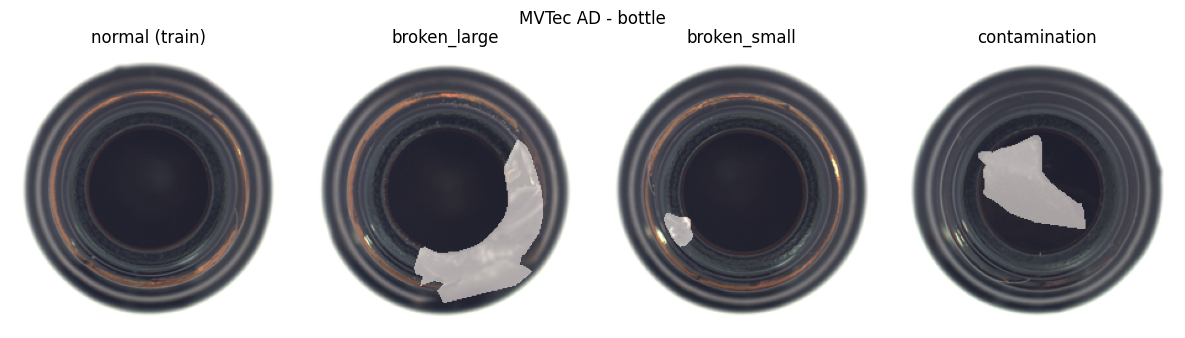

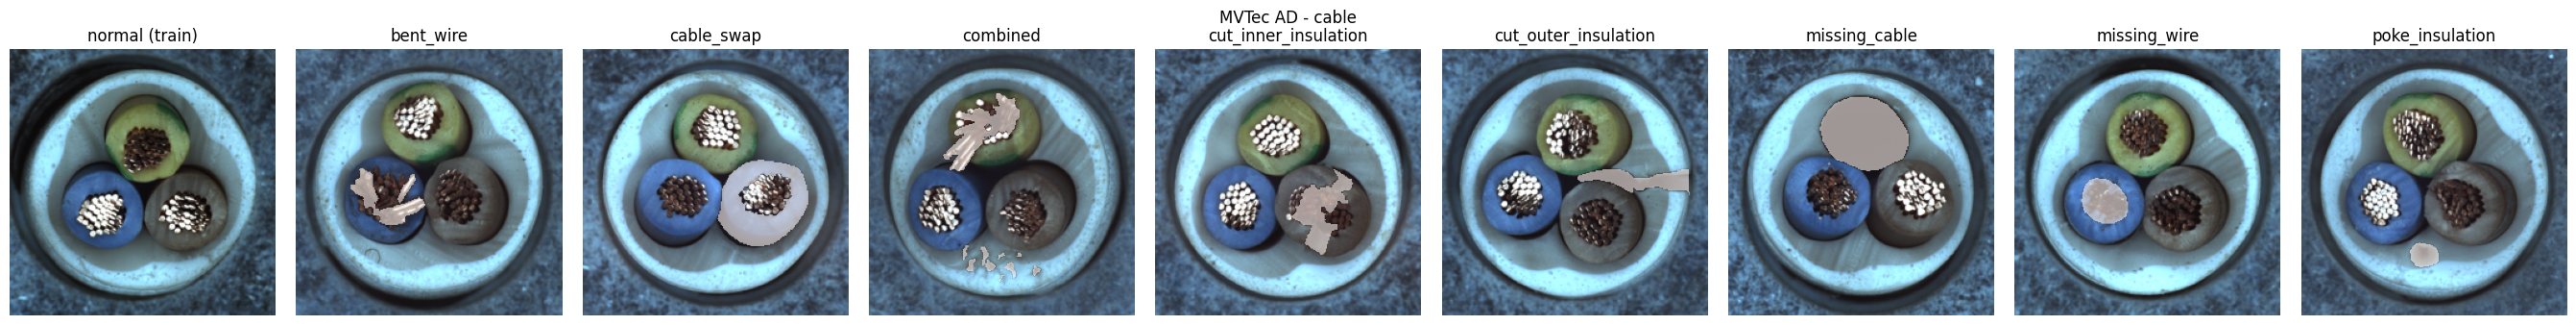

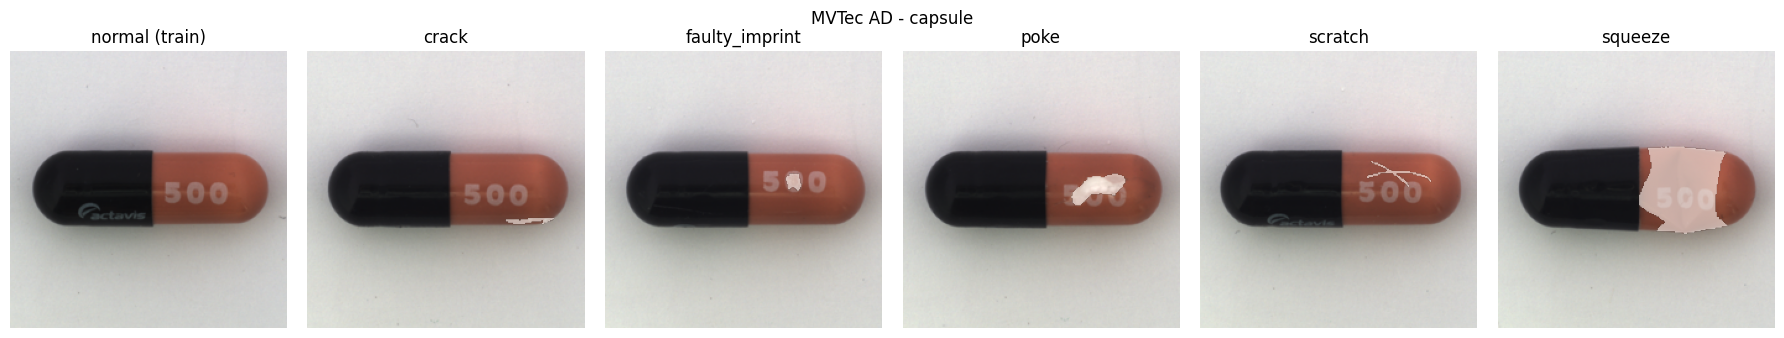

In [ ]:
def show_dataset_samples(category):
    """Show one normal training image and one example for every defect type with the mask in red."""
    train_ds = MVTecDataset(DATA_ROOT, category, "train", IMG_SIZE)
    test_ds = MVTecDataset(DATA_ROOT, category, "test", IMG_SIZE)
    first = {}
    for s in test_ds.samples:
        if s["type"] != "good":
            first.setdefault(s["type"], s)

    n = 1 + len(first)
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3.4))
    axes = np.atleast_1d(axes)
    axes[0].imshow(train_ds.load_pil(train_ds.samples[0]["img"])); axes[0].set_title("normal (train)")
    for ax, (t, s) in zip(axes[1:], first.items()):
        ax.imshow(test_ds.load_pil(s["img"]))
        m = np.asarray(Image.open(s["mask"]).convert("L").resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)) > 0
        ax.imshow(np.ma.masked_where(~m, m), cmap="Reds", alpha=0.6)
        ax.set_title(t)
    for ax in axes: ax.axis("off")
    plt.suptitle(f"MVTec AD - {category}"); plt.tight_layout(); plt.show()

for c in CATEGORIES[:3]:
    show_dataset_samples(c)

## Step 4 - Feature extractors (the heart of the project)

### 4.1 Vision Transformer (ViT) in simple words
* The image is cut into **16x16 patches** (224/16 = 14, so 14x14 = 196 patches).
* Each patch becomes a vector (**patch embedding**) + a **position embedding**, and all patches go through **12 transformer blocks**.
* In each block, **self-attention** lets every patch look at every other patch, so each patch feature also knows the **global context** (a CNN only sees a small local window in early layers).
* We use **DINO ViT-B/16**: trained by self-supervision (no labels), and its patch features are very good at describing local texture/structure, which is what anomaly detection needs.
* We take features from **intermediate blocks** (8 and 11): deeper blocks become too "semantic/class-specific", while middle blocks still keep fine local detail where small defects live.

In [ ]:
class ViTExtractor(torch.nn.Module):
    """Frozen DINO ViT. Returns a patch-feature map of shape (B, C, h, w)."""

    def __init__(self, name=VIT_NAME, layers=VIT_LAYERS):
        super().__init__()
        self.model = ViTModel.from_pretrained(name, add_pooling_layer=False).eval()
        for p in self.model.parameters():
            p.requires_grad = False                 # frozen: we never train the ViT
        self.layers = layers

    @torch.no_grad()
    def forward(self, x):
        out = self.model(pixel_values=x, output_hidden_states=True, interpolate_pos_encoding=True)
        # hidden_states[0] = embeddings, hidden_states[k] = output of transformer block k
        feats = [out.hidden_states[l][:, 1:, :] for l in self.layers]   # [:, 1:] removes the [CLS] token, keeps patch tokens
        f = torch.cat(feats, dim=-1)                                     # (B, N_patches, C) - concatenate chosen layers
        B, N, C = f.shape
        h = w = int(math.sqrt(N))                                        # 196 patches -> 14 x 14 grid
        return f.transpose(1, 2).reshape(B, C, h, w)                     # back to an image-like grid (B, C, h, w)


class CNNExtractor(torch.nn.Module):
    """Baseline: frozen WideResNet-50 (ImageNet). Uses layer2 + layer3 features as in PatchCore."""

    def __init__(self):
        super().__init__()
        self.net = wide_resnet50_2(weights=Wide_ResNet50_2_Weights.IMAGENET1K_V1).eval()
        for p in self.net.parameters():
            p.requires_grad = False

    @torch.no_grad()
    def forward(self, x):
        n = self.net
        x = n.maxpool(n.relu(n.bn1(n.conv1(x))))
        x = n.layer1(x)
        f2 = n.layer2(x)                                                 # (B, 512, 28, 28)  finer details
        f3 = n.layer3(f2)                                                # (B, 1024, 14, 14) more semantic
        f3 = F.interpolate(f3, size=f2.shape[-2:], mode="bilinear", align_corners=False)   # make both 28x28
        return torch.cat([f2, f3], dim=1)                                # (B, 1536, 28, 28)


@torch.no_grad()
def get_features(extractor, x):
    """Backbone features + 3x3 local average pooling (each patch also 'sees' its neighbours -> more stable)."""
    f = extractor(x.to(DEVICE))
    return F.avg_pool2d(f, kernel_size=3, stride=1, padding=1)


vit = ViTExtractor().to(DEVICE)
EXTRACTORS = {"vit": vit}
if RUN_CNN_BASELINE:
    EXTRACTORS["cnn"] = CNNExtractor().to(DEVICE)

# quick shape check
_x = torch.randn(2, 3, IMG_SIZE, IMG_SIZE)
for k, e in EXTRACTORS.items():
    print(k, "feature map shape:", tuple(get_features(e, _x).shape), "(B, C, h, w)")

config.json:   0%|          | 0.00/454 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  343MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

Downloading: "https://download.pytorch.org/models/wide_resnet50_2-95faca4d.pth" to /root/.cache/torch/hub/checkpoints/wide_resnet50_2-95faca4d.pth




  0%|          | 0.00/132M [00:00<?, ?B/s]

  5%|▍         | 6.38M/132M [00:00<00:01, 66.1MB/s]

 14%|█▍        | 18.4M/132M [00:00<00:01, 101MB/s] 

 25%|██▌       | 33.4M/132M [00:00<00:00, 126MB/s]

 36%|███▌      | 47.6M/132M [00:00<00:00, 135MB/s]

 47%|████▋     | 61.8M/132M [00:00<00:00, 139MB/s]

 59%|█████▊    | 77.2M/132M [00:00<00:00, 147MB/s]

 71%|███████   | 93.0M/132M [00:00<00:00, 153MB/s]

 83%|████████▎ | 110M/132M [00:00<00:00, 161MB/s] 

100%|██████████| 132M/132M [00:00<00:00, 147MB/s]


vit feature map shape: (2, 1536, 14, 14) (B, C, h, w)
cnn feature map shape: (2, 1536, 28, 28) (B, C, h, w)


## Step 5 - Memory bank, coreset and anomaly scoring

* **Memory bank** = patch features of all normal training images. For one category this can be 50,000 to 300,000 vectors, too many to search quickly.
* **Greedy coreset (k-center)** keeps a small subset (10%) that still **covers** the whole feature space: we repeatedly pick the patch that is **farthest** from all patches selected so far. (We do it on a random low-dimensional projection to make it fast.)
* **Anomaly score of a patch** = distance to its **nearest** neighbour in the memory bank. Normal patches have a close neighbour; defect patches do not.

In [ ]:
@torch.no_grad()
def greedy_coreset(feats, ratio=CORESET_RATIO, proj_dim=128, seed=SEED):
    """Greedy k-center coreset subsampling. feats: (N, C) tensor on GPU. Returns (N*ratio, C)."""
    N, C = feats.shape
    n_select = max(1, int(N * ratio))
    if n_select >= N:
        return feats

    # Random projection to a small dimension: distances are roughly preserved, but 10x faster
    g = torch.Generator().manual_seed(seed)
    proj = (torch.randn(C, proj_dim, generator=g) / math.sqrt(proj_dim)).to(feats.device)
    z = feats @ proj                                                    # (N, proj_dim)

    selected = torch.empty(n_select, dtype=torch.long, device=feats.device)
    selected[0] = int(torch.randint(0, N, (1,), generator=g))           # start from a random patch
    min_dist = ((z - z[selected[0]]) ** 2).sum(1)                       # distance of every patch to the selected set

    for i in range(1, n_select):
        idx = torch.argmax(min_dist)                                    # farthest patch = least covered so far
        selected[i] = idx
        d = ((z - z[idx]) ** 2).sum(1)
        min_dist = torch.minimum(min_dist, d)                           # update "distance to selected set"
    return feats[selected]


@torch.no_grad()
def nn_distance(query, bank, chunk=4096):
    """For each row of `query` (M,C): Euclidean distance to the nearest row of `bank` (K,C). Chunked to save memory."""
    out = []
    for i in range(0, query.shape[0], chunk):
        d = torch.cdist(query[i:i + chunk], bank)                       # (chunk, K)
        out.append(d.min(dim=1).values)                                 # nearest neighbour distance
    return torch.cat(out)


@torch.no_grad()
def make_anomaly_maps(extractor, x, bank):
    """Batch of images -> (B, IMG_SIZE, IMG_SIZE) numpy anomaly maps (higher = more anomalous)."""
    f = get_features(extractor, x)                                      # (B, C, h, w)
    B, C, h, w = f.shape
    q = f.permute(0, 2, 3, 1).reshape(-1, C)                            # every patch is one query vector
    dist = nn_distance(q, bank).reshape(B, 1, h, w)                     # patch-level anomaly score
    up = F.interpolate(dist, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[:, 0]   # to pixel level
    up = up.cpu().numpy()
    return np.stack([gaussian_filter(a, sigma=GAUSS_SIGMA) for a in up])                              # smooth

## Step 6 - Train (build memory bank) + evaluate one category
"Training" here = extracting normal features and building the memory bank (no gradient descent).
Evaluation = Image AUROC + Pixel AUROC on the official test set.
Also saves the memory bank and a decision threshold, so we can reuse them later for a demo/app without recomputing.

In [ ]:
STORE = {}   # keeps maps/labels of each (backbone, category) for plots later


def run_category(extractor, category, tag, save=True, keep=True):
    t0 = time.time()

    # ---------- (a) Build the memory bank from NORMAL training images ----------
    train_ds = MVTecDataset(DATA_ROOT, category, "train", IMG_SIZE)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
    feats = []
    for x, *_ in train_loader:
        f = get_features(extractor, x)                                  # (B, C, h, w)
        feats.append(f.permute(0, 2, 3, 1).reshape(-1, f.shape[1]))     # flatten to a list of patch vectors
    feats = torch.cat(feats, 0)
    n_patches = feats.shape[0]
    bank = greedy_coreset(feats)                                        # compress the memory bank
    del feats

    # ---------- (b) Score every TEST image ----------
    test_ds = MVTecDataset(DATA_ROOT, category, "test", IMG_SIZE)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
    maps, masks, labels, paths, types = [], [], [], [], []
    for x, m, y, p, d in test_loader:
        maps.append(make_anomaly_maps(extractor, x, bank))
        masks.append(m.numpy().astype(np.uint8))
        labels.append(y.numpy()); paths += list(p); types += list(d)
    maps = np.concatenate(maps); masks = np.concatenate(masks); labels = np.concatenate(labels)

    # ---------- (c) Metrics ----------
    img_scores = maps.reshape(len(maps), -1).max(1)                     # image score = most anomalous pixel
    img_auc = roc_auc_score(labels, img_scores)                         # normal vs defective images
    pix_auc = roc_auc_score(masks.reshape(-1), maps.reshape(-1))        # defect pixels vs normal pixels

    # Decision threshold = point of the ROC curve farthest from the diagonal (Youden's J)
    fpr, tpr, thr = roc_curve(labels, img_scores)
    threshold = float(thr[np.argmax(tpr - fpr)])
    acc = float(((img_scores >= threshold).astype(int) == labels).mean())

    # ---------- (d) Save / keep ----------
    if save:
        torch.save(dict(bank=bank.half().cpu(), threshold=threshold, img_size=IMG_SIZE, tag=tag,
                        score_min=float(maps.min()), score_max=float(maps.max())),
                   f"{OUT_DIR}/banks/{tag}_{category}.pt")
    if keep:
        STORE[(tag, category)] = dict(maps=maps, masks=masks, labels=labels, scores=img_scores,
                                      paths=paths, types=types, thr=threshold)
    res = dict(category=category, backbone=tag, image_auroc=img_auc, pixel_auroc=pix_auc,
               threshold=threshold, accuracy_at_thr=acc, bank_size=int(bank.shape[0]),
               train_patches=n_patches, seconds=round(time.time() - t0, 1))
    del bank
    torch.cuda.empty_cache()
    return res

## Step 7 - Run all categories (ViT, then CNN baseline)
First run with `CATEGORIES = ["bottle"]` to check everything works. A full run on a free T4 GPU can take a while, so be patient.

In [ ]:
all_results = []
for tag, extractor in EXTRACTORS.items():
    for cat in tqdm(CATEGORIES, desc=f"Backbone = {tag}"):
        r = run_category(extractor, cat, tag)
        all_results.append(r)
        print(f"[{tag}] {cat:12s} image AUROC = {r['image_auroc']:.3f} | pixel AUROC = {r['pixel_auroc']:.3f} | {r['seconds']}s")

results = pd.DataFrame(all_results)
results.to_csv(f"{OUT_DIR}/results_all.csv", index=False)

Backbone = vit:   0%|          | 0/15 [00:00<?, ?it/s]

[vit] bottle       image AUROC = 0.999 | pixel AUROC = 0.973 | 13.7s
[vit] cable        image AUROC = 0.992 | pixel AUROC = 0.975 | 24.1s
[vit] capsule      image AUROC = 0.869 | pixel AUROC = 0.954 | 22.0s
[vit] carpet       image AUROC = 0.946 | pixel AUROC = 0.975 | 26.3s
[vit] grid         image AUROC = 0.962 | pixel AUROC = 0.926 | 14.8s
[vit] hazelnut     image AUROC = 0.992 | pixel AUROC = 0.985 | 32.6s
[vit] leather      image AUROC = 1.000 | pixel AUROC = 0.988 | 22.3s
[vit] metal_nut    image AUROC = 0.992 | pixel AUROC = 0.981 | 13.6s
[vit] pill         image AUROC = 0.945 | pixel AUROC = 0.976 | 21.5s
[vit] screw        image AUROC = 0.793 | pixel AUROC = 0.860 | 21.8s
[vit] tile         image AUROC = 1.000 | pixel AUROC = 0.938 | 18.0s
[vit] toothbrush   image AUROC = 0.908 | pixel AUROC = 0.978 | 7.2s
[vit] transistor   image AUROC = 0.978 | pixel AUROC = 0.983 | 20.4s
[vit] wood         image AUROC = 0.958 | pixel AUROC = 0.908 | 21.1s
[vit] zipper       image AUROC = 0.

Backbone = cnn:   0%|          | 0/15 [00:00<?, ?it/s]

[cnn] bottle       image AUROC = 1.000 | pixel AUROC = 0.985 | 41.3s
[cnn] cable        image AUROC = 0.994 | pixel AUROC = 0.987 | 60.1s
[cnn] capsule      image AUROC = 0.988 | pixel AUROC = 0.988 | 52.8s
[cnn] carpet       image AUROC = 0.999 | pixel AUROC = 0.990 | 78.4s
[cnn] grid         image AUROC = 0.969 | pixel AUROC = 0.975 | 58.0s
[cnn] hazelnut     image AUROC = 1.000 | pixel AUROC = 0.987 | 127.0s
[cnn] leather      image AUROC = 1.000 | pixel AUROC = 0.992 | 59.7s
[cnn] metal_nut    image AUROC = 0.998 | pixel AUROC = 0.986 | 44.4s
[cnn] pill         image AUROC = 0.952 | pixel AUROC = 0.978 | 66.1s
[cnn] screw        image AUROC = 0.940 | pixel AUROC = 0.987 | 85.5s
[cnn] tile         image AUROC = 1.000 | pixel AUROC = 0.955 | 51.5s
[cnn] toothbrush   image AUROC = 0.919 | pixel AUROC = 0.989 | 9.4s
[cnn] transistor   image AUROC = 0.999 | pixel AUROC = 0.979 | 48.7s
[cnn] wood         image AUROC = 0.989 | pixel AUROC = 0.940 | 59.0s
[cnn] zipper       image AUROC = 0

## Step 8 - Results tables

In [ ]:
def pivot(metric):
    t = results.pivot(index="category", columns="backbone", values=metric).reindex(CATEGORIES)
    t.loc["MEAN"] = t.mean()
    return t.round(4)

print("IMAGE-level AUROC (higher is better)"); display(pivot("image_auroc"))
print("PIXEL-level AUROC (higher is better)"); display(pivot("pixel_auroc"))

IMAGE-level AUROC (higher is better)


backbone,cnn,vit
category,,
bottle,1.0000,0.9992
cable,0.9944,0.9921
capsule,0.9876,0.8688
carpet,0.9992,0.9458
grid,0.9691,0.9624
hazelnut,1.0000,0.9921
leather,1.0000,1.0000
metal_nut,0.9980,0.9922
pill,0.9523,0.9446


PIXEL-level AUROC (higher is better)


backbone,cnn,vit
category,,
bottle,0.9850,0.9727
cable,0.9867,0.9750
capsule,0.9879,0.9544
carpet,0.9902,0.9750
grid,0.9752,0.9264
hazelnut,0.9870,0.9846
leather,0.9920,0.9877
metal_nut,0.9863,0.9809
pill,0.9775,0.9764


## Step 9 - Graphs: ViT vs CNN

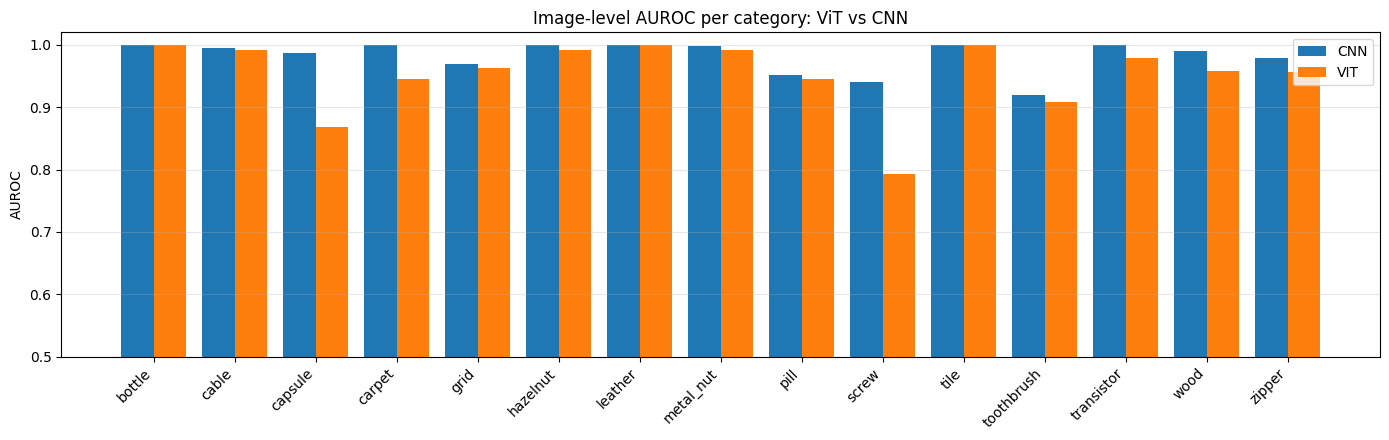

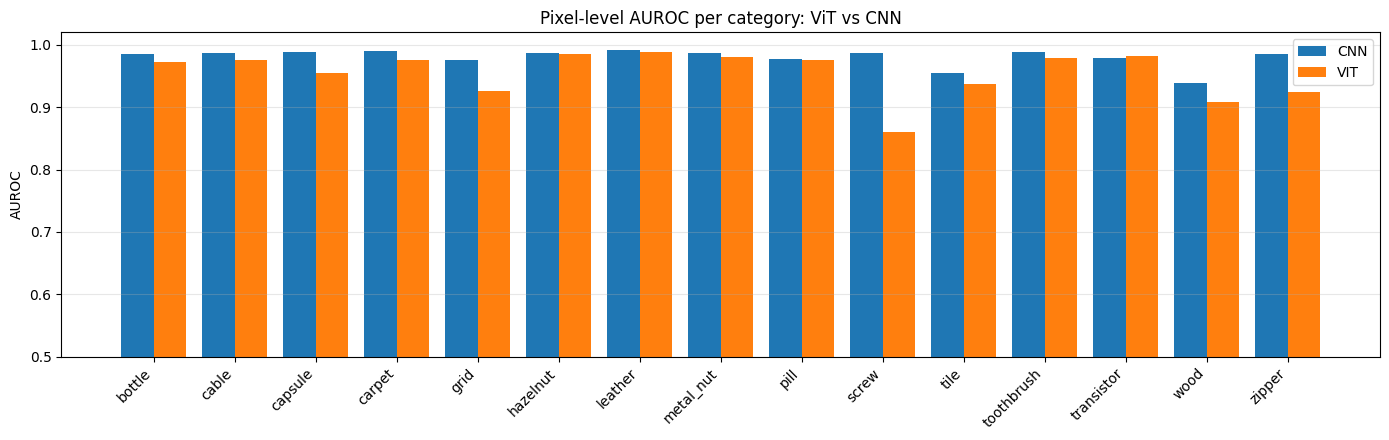

In [ ]:
def compare_plot(metric, title):
    t = results.pivot(index="category", columns="backbone", values=metric).reindex(CATEGORIES)
    x = np.arange(len(t)); w = 0.4
    plt.figure(figsize=(14, 4.5))
    for i, col in enumerate(t.columns):
        plt.bar(x + (i - (len(t.columns) - 1) / 2) * w, t[col], w, label=col.upper())
    plt.xticks(x, t.index, rotation=45, ha="right"); plt.ylim(0.5, 1.02)
    plt.ylabel("AUROC"); plt.title(title); plt.legend(); plt.grid(axis="y", alpha=0.3)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{metric}_comparison.png", dpi=150); plt.show()

compare_plot("image_auroc", "Image-level AUROC per category: ViT vs CNN")
compare_plot("pixel_auroc", "Pixel-level AUROC per category: ViT vs CNN")

## Step 10 - Visual results (anomaly heat maps)
Columns: input, ground-truth defect, predicted anomaly map, regions the model marks as anomalous.

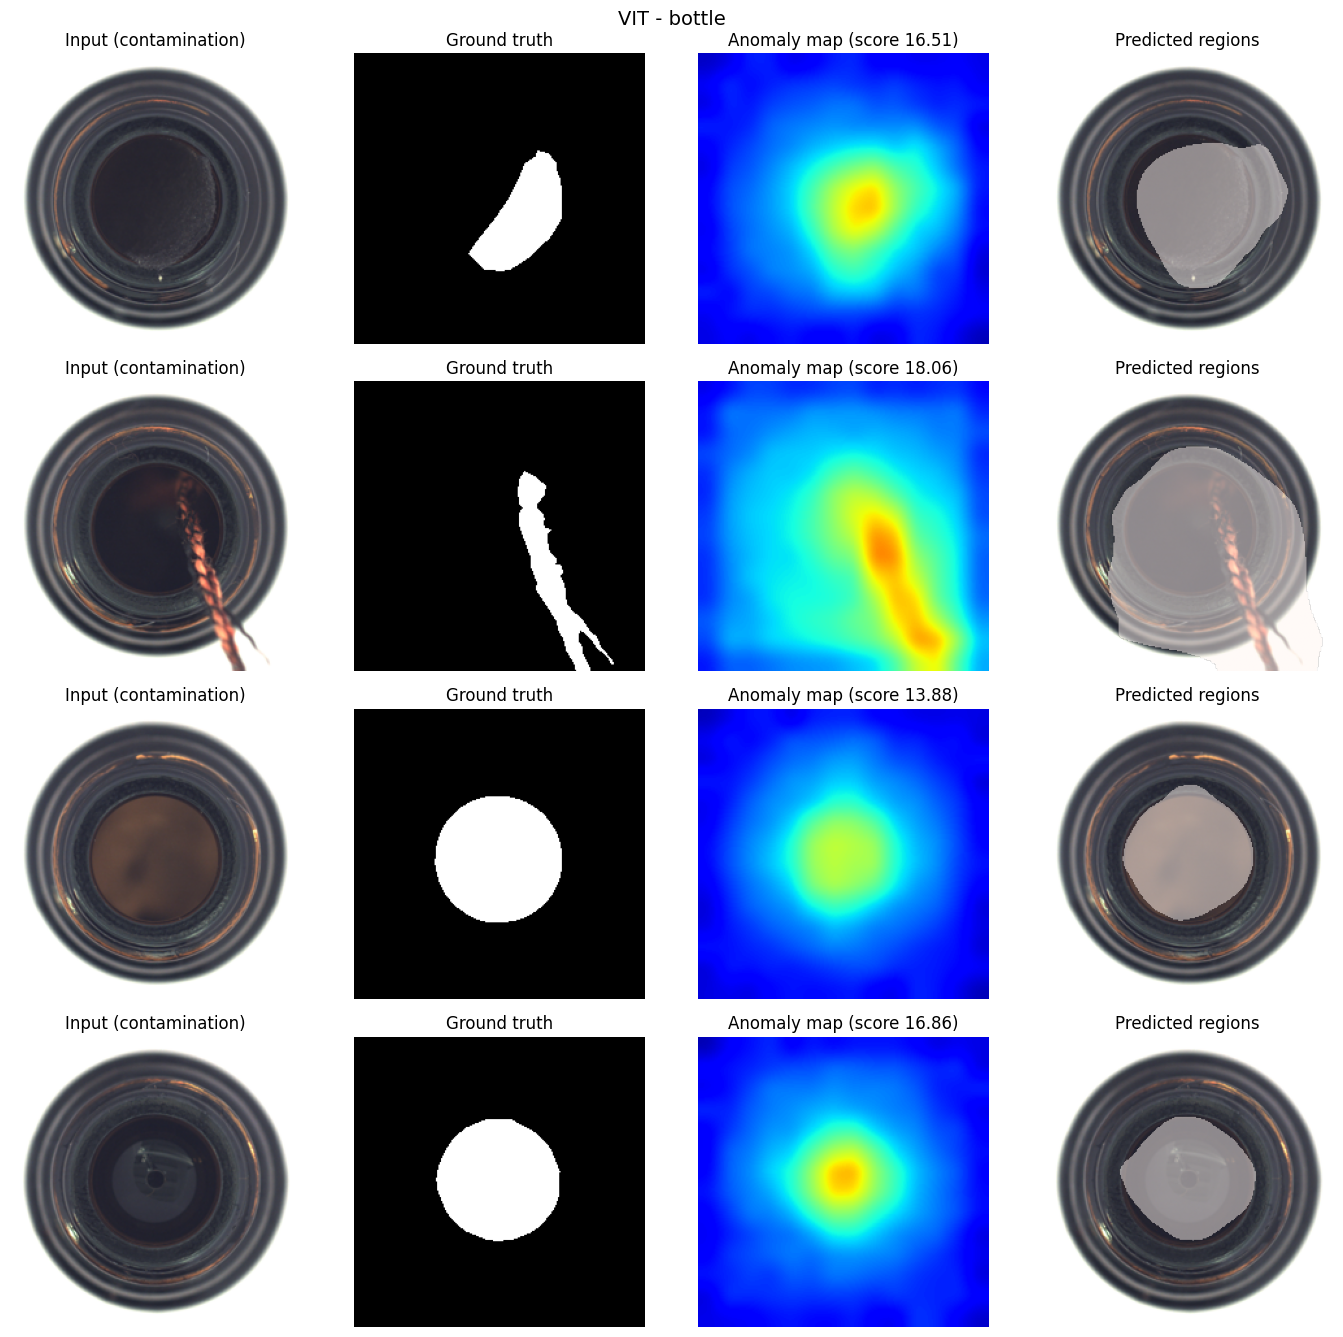

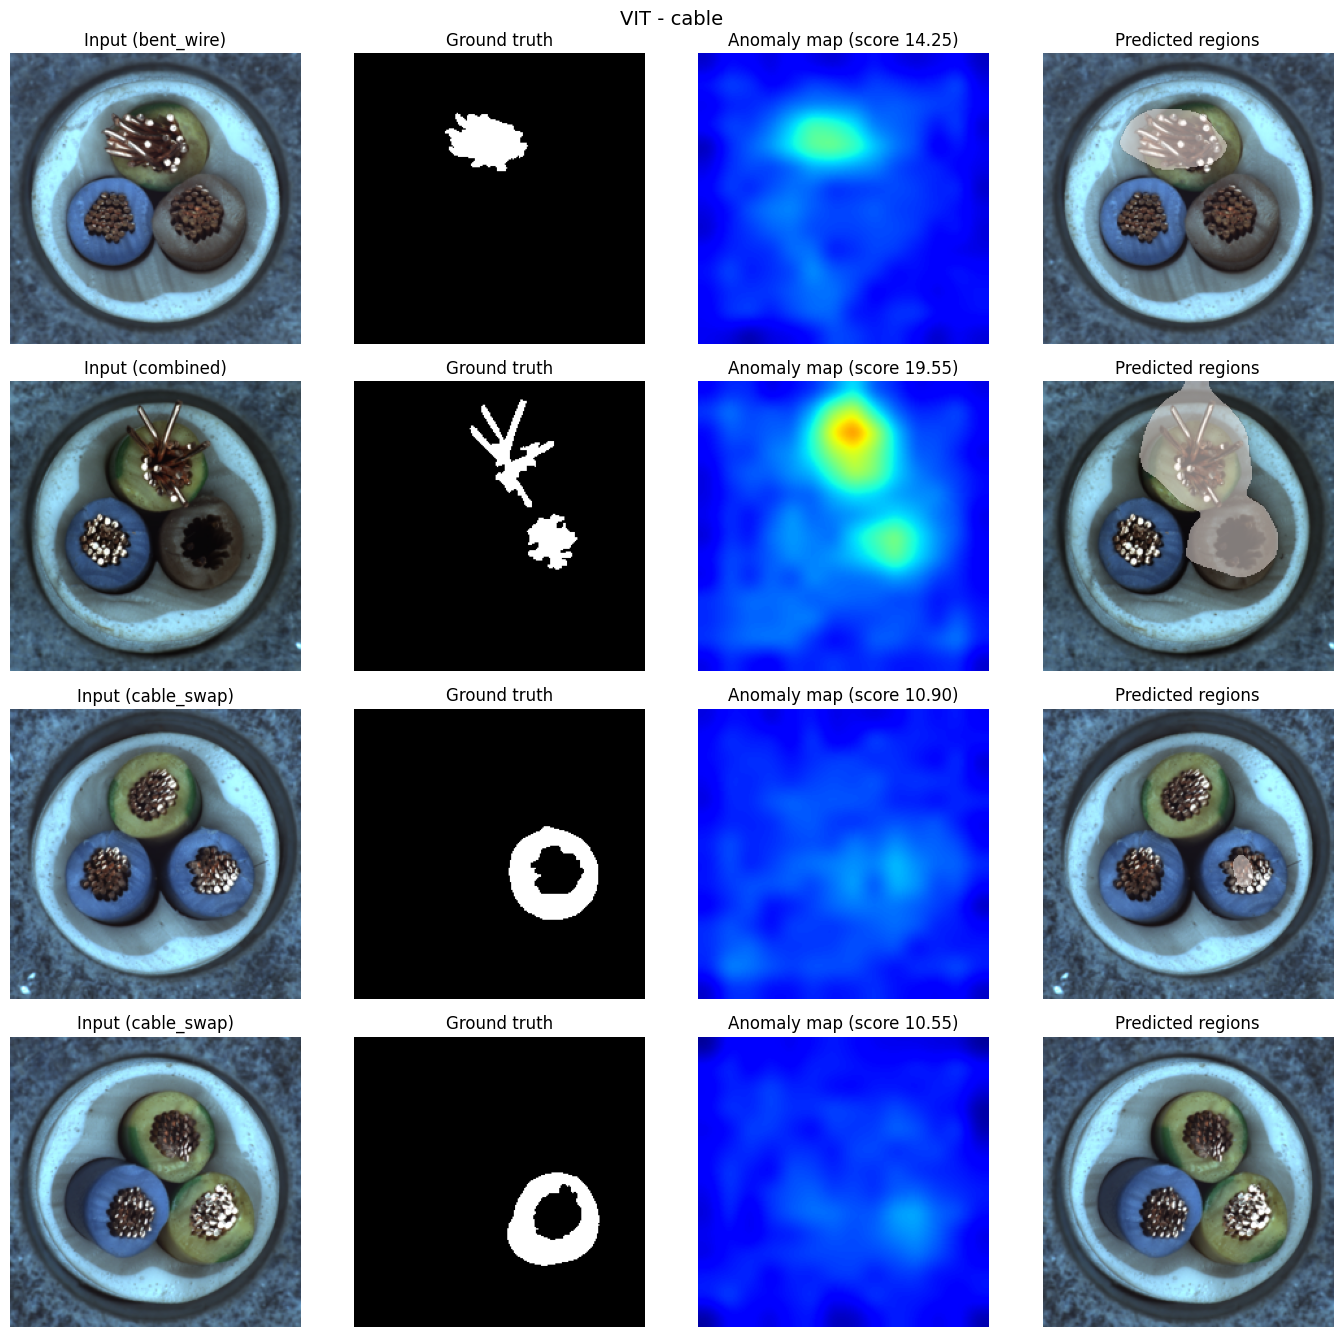

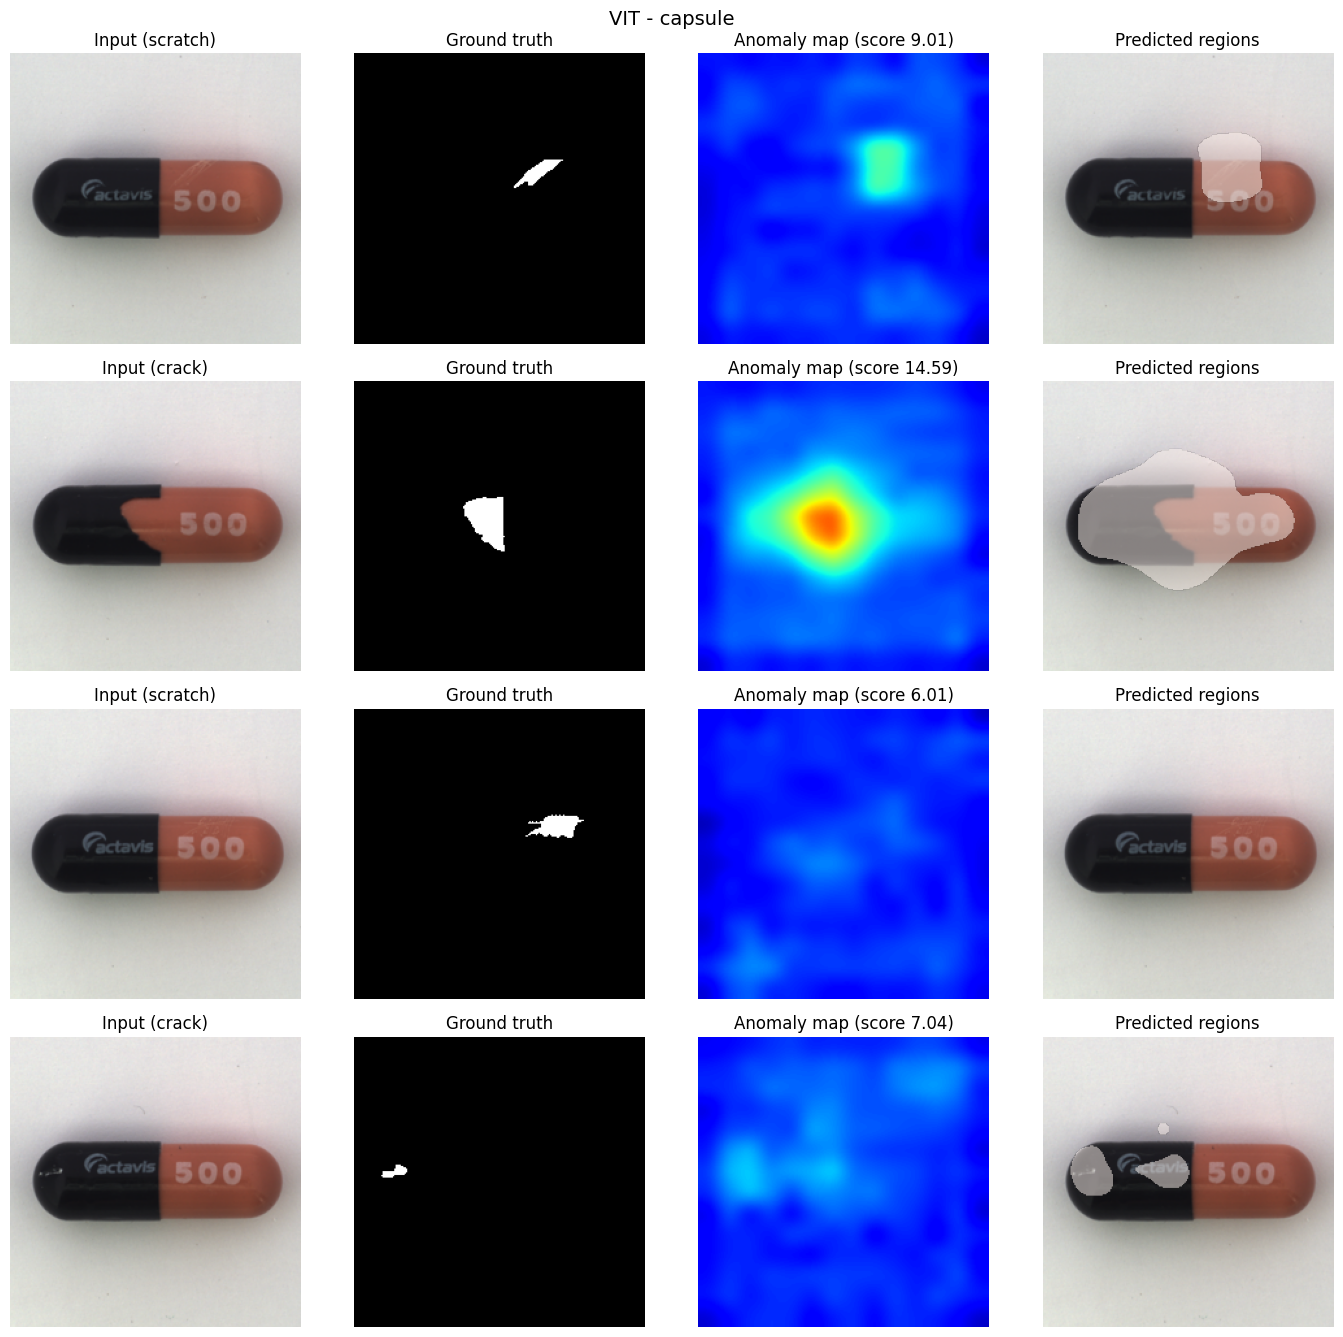

In [ ]:
def show_examples(tag, category, n=4, seed=0):
    d = STORE[(tag, category)]
    rng = np.random.RandomState(seed)
    defect_idx = np.where(d["labels"] == 1)[0]
    pick = rng.choice(defect_idx, min(n, len(defect_idx)), replace=False)
    vmin, vmax = d["maps"].min(), d["maps"].max()                      # same color scale for all images

    fig, axes = plt.subplots(len(pick), 4, figsize=(14, 3.4 * len(pick)))
    axes = np.atleast_2d(axes)
    for r, i in enumerate(pick):
        img = Image.open(d["paths"][i]).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
        pred = d["maps"][i] > d["thr"]
        axes[r, 0].imshow(img);                                  axes[r, 0].set_title(f"Input ({d['types'][i]})")
        axes[r, 1].imshow(d["masks"][i], cmap="gray");           axes[r, 1].set_title("Ground truth")
        axes[r, 2].imshow(d["maps"][i], cmap="jet", vmin=vmin, vmax=vmax); axes[r, 2].set_title(f"Anomaly map (score {d['scores'][i]:.2f})")
        axes[r, 3].imshow(img); axes[r, 3].imshow(np.ma.masked_where(~pred, pred), cmap="Reds", alpha=0.5)
        axes[r, 3].set_title("Predicted regions")
        for a in axes[r]: a.axis("off")
    plt.suptitle(f"{tag.upper()} - {category}", fontsize=14); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/examples_{tag}_{category}.png", dpi=130); plt.show()

for cat in CATEGORIES[:3]:          # change the list to see other categories
    show_examples("vit", cat)

### ROC curves and score distribution (normal vs defective)

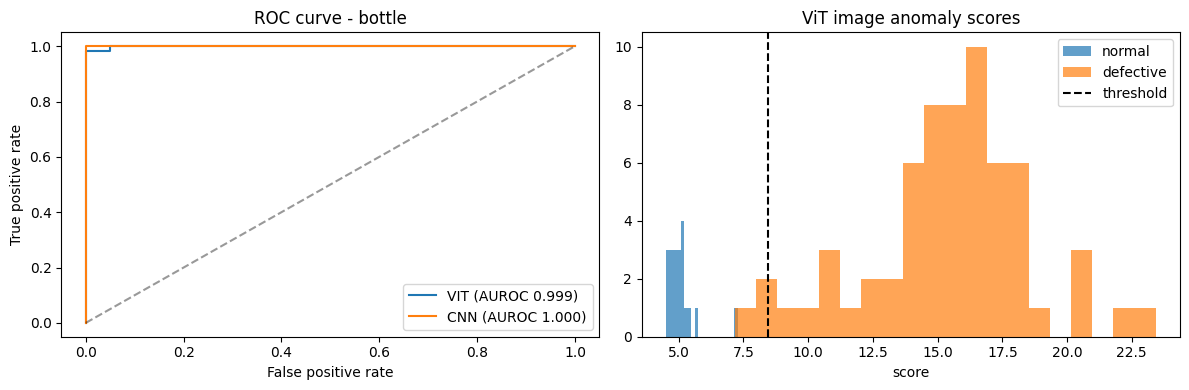

In [ ]:
def show_roc_and_hist(category):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for tag in EXTRACTORS:
        d = STORE[(tag, category)]
        fpr, tpr, _ = roc_curve(d["labels"], d["scores"])
        ax[0].plot(fpr, tpr, label=f"{tag.upper()} (AUROC {roc_auc_score(d['labels'], d['scores']):.3f})")
    ax[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
    ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
    ax[0].set_title(f"ROC curve - {category}"); ax[0].legend()

    d = STORE[("vit", category)]
    ax[1].hist(d["scores"][d["labels"] == 0], bins=20, alpha=0.7, label="normal")
    ax[1].hist(d["scores"][d["labels"] == 1], bins=20, alpha=0.7, label="defective")
    ax[1].axvline(d["thr"], color="k", ls="--", label="threshold")
    ax[1].set_title("ViT image anomaly scores"); ax[1].set_xlabel("score"); ax[1].legend()
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/roc_hist_{category}.png", dpi=130); plt.show()

show_roc_and_hist(CATEGORIES[0])

## Step 11 - Ablation study (which ViT layers are best?)
An ablation = change **one thing** and see what happens. This makes the report scientific.
We test early, middle, late and combined blocks on one category.

In [ ]:
ABLATION_CATEGORY = CATEGORIES[0]
layer_options = {"block 4 (early)": [4], "block 8 (middle)": [8], "block 11 (late)": [11],
                 "blocks 8+11 (ours)": [8, 11], "blocks 4+8+11": [4, 8, 11]}

abl = []
for name, layers in layer_options.items():
    vit.layers = layers
    r = run_category(vit, ABLATION_CATEGORY, "vit", save=False, keep=False)    # save=False: do not overwrite saved banks
    abl.append(dict(layers=name, image_auroc=round(r["image_auroc"], 4), pixel_auroc=round(r["pixel_auroc"], 4)))
vit.layers = VIT_LAYERS                                                        # restore the original setting
ablation = pd.DataFrame(abl)
ablation.to_csv(f"{OUT_DIR}/ablation_layers.csv", index=False)
print(f"Ablation on '{ABLATION_CATEGORY}'"); display(ablation)

Ablation on 'bottle'


,layers,image_auroc,pixel_auroc
0,block 4 (early),1.0000,0.9838
1,block 8 (middle),1.0000,0.9752
2,block 11 (late),0.9992,0.9697
3,blocks 8+11 (ours),0.9992,0.9727
4,blocks 4+8+11,0.9992,0.9743


## Step 12 - Predict on a single image (inference)
Loads the saved memory bank of a category and checks one image. We will reuse this function for the web app (UI) later.

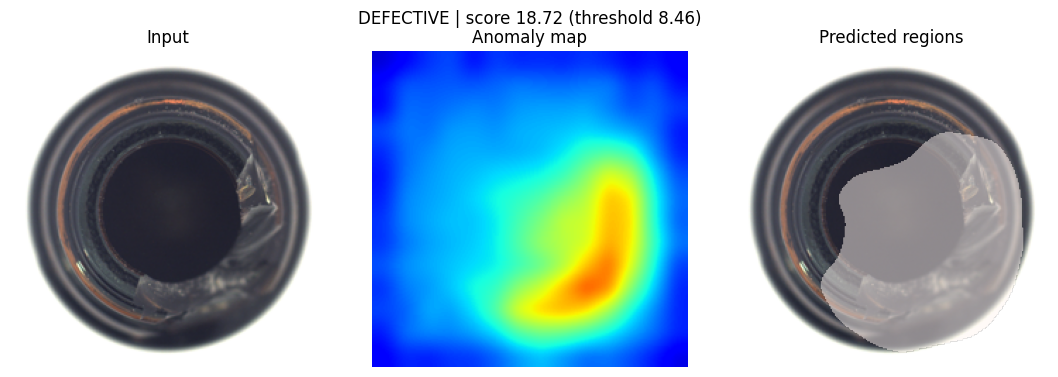

(18.721921920776367,
 True,
 array([[2.5193727, 2.5212405, 2.525299 , ..., 3.246393 , 3.243011 ,
         3.2414546],
        [2.5216155, 2.5234857, 2.527549 , ..., 3.2475061, 3.2441187,
         3.24256  ],
        [2.5264885, 2.5283637, 2.532438 , ..., 3.2499247, 3.2465255,
         3.2449613],
        ...,
        [3.312339 , 3.3143828, 3.3188233, ..., 2.8628151, 2.857898 ,
         2.8556352],
        [3.3093152, 3.3113525, 3.315779 , ..., 2.856903 , 2.8519914,
         2.849731 ],
        [3.3079236, 3.3099577, 3.3143778, ..., 2.854182 , 2.849273 ,
         2.8470135]], dtype=float32))

In [ ]:
@torch.no_grad()
def predict_image(image_path, category, tag="vit", show=True):
    ckpt = torch.load(f"{OUT_DIR}/banks/{tag}_{category}.pt", map_location=DEVICE)
    bank = ckpt["bank"].float().to(DEVICE)

    img = Image.open(image_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC)
    x = torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1).float() / 255.0
    x = ((x - MEAN) / STD).unsqueeze(0)

    amap = make_anomaly_maps(EXTRACTORS[tag], x, bank)[0]
    score = float(amap.max())
    is_defect = score >= ckpt["threshold"]

    if show:
        fig, ax = plt.subplots(1, 3, figsize=(11, 3.8))
        ax[0].imshow(img); ax[0].set_title("Input")
        ax[1].imshow(amap, cmap="jet", vmin=ckpt["score_min"], vmax=ckpt["score_max"]); ax[1].set_title("Anomaly map")
        pred = amap > ckpt["threshold"]
        ax[2].imshow(img); ax[2].imshow(np.ma.masked_where(~pred, pred), cmap="Reds", alpha=0.5); ax[2].set_title("Predicted regions")
        for a in ax: a.axis("off")
        plt.suptitle(f"{'DEFECTIVE' if is_defect else 'NORMAL'} | score {score:.2f} (threshold {ckpt['threshold']:.2f})")
        plt.tight_layout(); plt.show()
    return score, is_defect, amap

# Demo: take a defective test image of the first category
_cat = CATEGORIES[0]
_ds = MVTecDataset(DATA_ROOT, _cat, "test", IMG_SIZE)
_sample = next(s for s in _ds.samples if s["label"] == 1)
predict_image(_sample["img"], _cat)

## Discussion (use these points in your report)
1. **Why ViT works here:** self-attention gives every patch global context, so patch features describe both the local texture and its surroundings. DINO pretraining gives strong local features without labels.
2. **ViT vs CNN:** compare the mean image and pixel AUROC in Step 8. Check which categories are textures (carpet, grid, leather, tile, wood) and which are objects (bottle, cable, screw...) and discuss where each backbone wins.
3. **Ablation:** shows middle blocks keep more local detail than the last block. Report the table from Step 11.
4. **Limitations:** the ViT patch grid is coarse (14x14), so very small defects (e.g. screw, capsule) are harder. Higher resolution (e.g. IMG_SIZE = 448) or a smaller patch size can help but costs more memory and time.
5. **Future work:** higher input resolution, fine-tuning with synthetic anomalies, other backbones (DINOv2, CLIP), and deploying as a web app.

In [ ]:
# =====================================================================================
#  ViT-Inspect  |  Interactive Gradio UI   (run as a NEW CELL at the END of the notebook)
#  Needs: notebook Steps 1-5 executed in this runtime (functions) + Step 7 done (saved banks).
#  Theme: Jet Black #0A0A0A | Cerulean Blue #007BA7 | Neon Rose #FF2D95
# =====================================================================================
# !pip -q install "gradio>=5,<6"      # <- run once in its own cell first
import random, html
import gradio as gr

JET, BLUE, ROSE = "#0A0A0A", "#007BA7", "#FF2D95"
RNG = random.Random(7)
CMAP = plt.get_cmap("jet")                       # same colour map as the notebook heat maps
BANKS, TEST_CACHE = {}, {}                       # caches so the app stays fast

# ------------------------------- 1. BACKEND (model logic) -------------------------------
def available_categories():
    """Only categories whose memory bank was saved in the notebook (Step 6/7)."""
    return [c for c in ALL_CATEGORIES if os.path.exists(f"{OUT_DIR}/banks/vit_{c}.pt")] or ALL_CATEGORIES

def get_bank(tag, cat):
    """Load the saved memory bank + threshold once, then reuse."""
    if (tag, cat) not in BANKS:
        path = f"{OUT_DIR}/banks/{tag}_{cat}.pt"
        if not os.path.exists(path):
            raise gr.Error(f"No saved memory bank for {tag.upper()} / {cat}. Run the notebook for this category first.")
        ck = torch.load(path, map_location=DEVICE); ck["bank"] = ck["bank"].float()
        BANKS[(tag, cat)] = ck
    return BANKS[(tag, cat)]

@torch.no_grad()
def infer(pil, cat, tag):
    """PIL image -> anomaly map + score (same pipeline as notebook Step 5)."""
    ck = get_bank(tag, cat)
    img = pil.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC)
    x = torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1).float() / 255.0
    x = ((x - MEAN) / STD).unsqueeze(0)
    amap = make_anomaly_maps(EXTRACTORS[tag], x, ck["bank"])[0]
    return dict(img=img, amap=amap, score=float(amap.max()), thr=ck["threshold"],
                lo=ck["score_min"], hi=ck["score_max"], tag=tag)

def verdict_html(st, sens):
    """Big result card: blue = NORMAL, neon rose = DEFECTIVE, with a score-vs-threshold meter."""
    thr = st["thr"] * sens
    bad = st["score"] >= thr
    pct = min(100, st["score"] / (2 * thr) * 100)          # threshold marker sits at 50 %
    return (f'<div class="verdict {"bad" if bad else "ok"}"><div class="vw">{"DEFECTIVE" if bad else "NORMAL"}</div>'
            f'<div class="vs">{st["tag"].upper()} · score {st["score"]:.2f} · threshold {thr:.2f}</div>'
            f'<div class="meter"><div class="fill" style="width:{pct:.0f}%"></div><div class="mark"></div></div></div>')

def make_views(st, sens, opacity):
    """Heat-map overlay (opacity slider) and predicted regions (sensitivity slider)."""
    amap, base = st["amap"], np.asarray(st["img"])
    norm = np.clip((amap - st["lo"]) / (st["hi"] - st["lo"] + 1e-8), 0, 1)
    heat = (CMAP(norm)[..., :3] * 255).astype(np.uint8)
    blend = (base * (1 - opacity) + heat * opacity).astype(np.uint8)
    seg = base.copy(); pred = amap > st["thr"] * sens
    seg[pred] = (0.4 * seg[pred] + 0.6 * np.array([255, 45, 149])).astype(np.uint8)
    return Image.fromarray(blend), Image.fromarray(seg)

# ------------------------------- 2. UI EVENT FUNCTIONS -------------------------------
def analyse(img, cat, model):
    if img is None:
        raise gr.Error("Upload an image or press 🎲 Random test image")
    return infer(img, cat, model)

def render(st, sens, opacity):
    """Re-draw results from the cached state, so sliders update LIVE without re-running the model."""
    if st is None:
        return [gr.update()] * 5
    blend, seg = make_views(st, sens, opacity)
    path = f"{OUT_DIR}/heatmap_result.png"; blend.save(path)
    return verdict_html(st, sens), st["img"], blend, seg, path

def random_image(cat):
    """Pick a random official test image (normal or defective) from the dataset."""
    if cat not in TEST_CACHE:
        TEST_CACHE[cat] = MVTecDataset(DATA_ROOT, cat, "test", IMG_SIZE).samples
    return Image.open(RNG.choice(TEST_CACHE[cat])["img"]).convert("RGB")

def compare(img, cat):
    """Same image through ViT and CNN -> two verdicts + two heat maps."""
    if img is None:
        raise gr.Error("Upload an image or press 🎲 Random test image")
    out = []
    for tag in ["vit", "cnn"]:
        if tag not in EXTRACTORS:
            out += ["<div class='note'>CNN baseline was not run (RUN_CNN_BASELINE = False).</div>", None]; continue
        st = infer(img, cat, tag); out += [verdict_html(st, 1.0), make_views(st, 1.0, 0.5)[0]]
    return out

def dataset_gallery(cat):
    """One normal image + one example per defect type (mask in neon rose)."""
    tr = MVTecDataset(DATA_ROOT, cat, "train", IMG_SIZE); te = MVTecDataset(DATA_ROOT, cat, "test", IMG_SIZE)
    items, seen = [(tr.load_pil(tr.samples[0]["img"]), "normal (train)")], set()
    for s in te.samples:
        if s["type"] != "good" and s["type"] not in seen:
            seen.add(s["type"]); im = np.array(te.load_pil(s["img"]))
            m = np.asarray(Image.open(s["mask"]).convert("L").resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)) > 0
            im[m] = (0.4 * im[m] + 0.6 * np.array([255, 45, 149])).astype(np.uint8)
            items.append((Image.fromarray(im), s["type"]))
    return items

def load_results():
    """Tables/plots produced in notebook Steps 8-11."""
    f = f"{OUT_DIR}/results_all.csv"
    if not os.path.exists(f):
        return None, None, None
    r = pd.read_csv(f)
    def pv(m):
        t = r.pivot(index="category", columns="backbone", values=m); t.loc["MEAN"] = t.mean()
        return t.round(4).reset_index()
    abl = f"{OUT_DIR}/ablation_layers.csv"
    return pv("image_auroc"), pv("pixel_auroc"), (pd.read_csv(abl) if os.path.exists(abl) else None)

# ------------------------------- 3. STYLE (CSS + theme) -------------------------------
CSS = f"""
body{{background:radial-gradient(900px 420px at 90% -8%,rgba(255,45,149,.20),transparent),
 radial-gradient(900px 480px at -8% 0%,rgba(0,123,167,.28),transparent),{JET}!important;background-attachment:fixed!important}}
.gradio-container{{background:transparent!important;max-width:1240px!important;margin-left:auto!important;margin-right:auto!important;padding:16px 20px!important}}
.hero{{display:flex;align-items:center;justify-content:space-between;gap:24px;padding:26px 30px;margin-bottom:8px;
 border:1px solid {BLUE};border-radius:20px;background:linear-gradient(120deg,rgba(0,123,167,.18),rgba(255,45,149,.10));
 box-shadow:0 0 30px rgba(0,123,167,.35)}}
.hero h1{{margin:0;font-size:46px;font-weight:800;color:#fff;letter-spacing:1px;text-shadow:0 0 18px {ROSE}}}
.hero h1 span{{color:{ROSE}}} .hero p{{margin:6px 0 12px;color:#c9d6dd;font-size:16px}}
.chip{{display:inline-block;margin:3px 6px 0 0;padding:4px 12px;border-radius:999px;border:1px solid {BLUE};color:#9fdcf0;font-size:12px}}
.chip.r{{border-color:{ROSE};color:#ffb3d9}}
.verdict{{border-radius:18px;padding:18px 22px;text-align:center;border:2px solid;margin-bottom:6px}}
.verdict.ok{{border-color:{BLUE};background:rgba(0,123,167,.15);box-shadow:0 0 28px rgba(0,123,167,.55)}}
.verdict.bad{{border-color:{ROSE};background:rgba(255,45,149,.13);box-shadow:0 0 28px rgba(255,45,149,.6)}}
.vw{{font-size:40px;font-weight:800;letter-spacing:4px;color:#fff}} .vs{{color:#cfd8dc;font-size:14px;margin-top:2px}}
.meter{{position:relative;height:10px;border-radius:6px;background:#1c1c1c;margin-top:12px;overflow:hidden}}
.ok .fill{{height:100%;background:{BLUE}}} .bad .fill{{height:100%;background:{ROSE}}}
.mark{{position:absolute;left:50%;top:-2px;width:3px;height:14px;background:#fff}}
.card{{background:rgba(255,255,255,.04);border:1px solid rgba(0,123,167,.5);border-radius:16px;padding:16px 18px;color:#dbe6ec;margin-bottom:10px}}
.card h3{{margin:0 0 6px;color:{ROSE}}} .card b{{color:#7fd3ee}}
.steps{{display:grid;grid-template-columns:repeat(auto-fit,minmax(210px,1fr));gap:12px}}
.step{{border-left:4px solid {ROSE};background:rgba(0,123,167,.10);border-radius:12px;padding:12px 14px;color:#dbe6ec}}
.step i{{color:{ROSE};font-style:normal;font-weight:800;font-size:22px}}
.note{{color:#ffb3d9;padding:12px}}
button.primary,.primary{{box-shadow:0 0 16px rgba(0,123,167,.7)!important;font-weight:700!important}}
button[role=tab][aria-selected=true]{{color:{ROSE}!important;border-color:{ROSE}!important}}
footer{{display:none!important}} .foot{{text-align:center;color:#78909c;padding:14px;font-size:13px}}
"""

_dark = dict(body_background_fill=JET, background_fill_primary="#101417", background_fill_secondary="#0d1114",
             block_background_fill="#101417", block_border_color="#1f3a46", body_text_color="#e6eef2",
             block_label_background_fill="#101417", block_label_text_color="#7fd3ee", input_background_fill="#0d1114",
             button_primary_background_fill=BLUE, button_primary_background_fill_hover=ROSE, button_primary_text_color="#fff",
             button_secondary_background_fill="#16232a", button_secondary_text_color="#9fdcf0",
             slider_color=ROSE, border_color_primary="#1f3a46", table_even_background_fill="#101417", table_odd_background_fill="#0d1a20")
theme = gr.themes.Base(font=[gr.themes.GoogleFont("Poppins"), "sans-serif"]).set(
    **_dark, **{k + "_dark": v for k, v in _dark.items()})

HERO = f"""<div class="hero"><div><h1>ViT<span>-</span>Inspect</h1>
<p>Unsupervised industrial defect detection with a Vision Transformer · MVTec AD</p>
<span class="chip">DINO ViT-B/16</span><span class="chip r">Memory bank + coreset</span><span class="chip">15 categories</span><span class="chip r">MAAI901</span></div>
<svg width="170" height="130" viewBox="0 0 170 130">{''.join(f'<rect x="{10+c*30}" y="{8+r*30}" width="26" height="26" rx="5" fill="{ROSE if (r,c)==(1,3) else BLUE}" opacity="{1 if (r,c)==(1,3) else .35}"/>' for r in range(4) for c in range(5))}</svg></div>"""

ABOUT_DATA = """<div class="card"><h3>What is MVTec AD?</h3>
<b>MVTec Anomaly Detection</b> is the standard benchmark for industrial visual inspection (Bergmann et al., CVPR 2019, MVTec Software GmbH).
It has <b>over 5,000 high-resolution images</b> in <b>15 categories</b>: <b>5 textures</b> (carpet, grid, leather, tile, wood) and
<b>10 objects</b> (bottle, cable, capsule, hazelnut, metal_nut, pill, screw, toothbrush, transistor, zipper).</div>
<div class="card"><h3>Why is it special?</h3>
Training set = <b>only normal images</b>. Test set = normal + defective images with <b>pixel-accurate ground-truth masks</b>
(scratches, cracks, dents, contamination, missing parts...). This matches real factories, where defects are rare and unpredictable.</div>
<div class="card"><h3>Folder structure</h3><code>category/train/good · category/test/&lt;defect_type&gt; · category/ground_truth/&lt;defect_type&gt;</code><br>
Source: Hugging Face <b>foersben/mvtec-ad</b> · License: <b>CC BY-NC-SA 4.0</b> (non-commercial use only).</div>"""

STEPS = [("1", "Patchify", "Image is cut into 16×16 patches (14×14 grid)."), ("2", "ViT features", "Frozen DINO ViT gives each patch a vector with global context via self-attention."),
         ("3", "Memory bank", "Patch features of normal images only, compressed by greedy coreset (10 %)."),
         ("4", "Nearest neighbour", "Each test patch: distance to closest normal patch. Far = anomalous."),
         ("5", "Heat map + score", "Distances form the anomaly map; its maximum is the image score.")]
METHOD = ('<div class="steps">' + "".join(f'<div class="step"><i>{n}</i> <b>{t}</b><br>{d}</div>' for n, t, d in STEPS) + "</div>"
          '<div class="card" style="margin-top:12px"><h3>Why a ViT?</h3>Self-attention lets every patch see the whole image, so features describe both local texture and context. '
          'Middle blocks (8, 11) keep fine local detail, which is where small defects live. A CNN baseline (WideResNet-50) uses the same pipeline for a fair comparison.</div>')

def data_usage_html():
    """Explains exactly which images are used for training and which for testing."""
    d = dataset_summary()
    tr, tg, td = int(d.train_normal.sum()), int(d.test_normal.sum()), int(d.test_defective.sum())
    return (f'<div class="card"><h3>How the data is used: train vs test</h3><div class="steps">'
            f'<div class="step"><i>{tr:,}</i><br><b>TRAIN: normal only</b><br>Defect-free images build the memory bank. The model never sees a defective image or a mask while training.</div>'
            f'<div class="step"><i>{tg:,}</i><br><b>TEST: normal</b><br>New defect-free images, used to check false alarms.</div>'
            f'<div class="step"><i>{td:,}</i><br><b>TEST: defective</b><br>Images with real defects + pixel masks, used only for evaluation (AUROC).</div></div>'
            f'<small style="color:#9fb3bd">Counts for the {len(d)} categories loaded in this session. The decision threshold is picked from test scores (Youden\'s J), '
            f'so the demo accuracy is slightly optimistic; AUROC does not depend on it.</small></div>')

def split_plot():
    """Bar chart: train normal / test normal / test defective per category."""
    d = dataset_summary(); x = np.arange(len(d)); w = 0.27
    fig, ax = plt.subplots(figsize=(11, 3.8)); fig.patch.set_facecolor(JET); ax.set_facecolor(JET)
    ax.bar(x - w, d.train_normal, w, color=BLUE, label="train (normal only)")
    ax.bar(x, d.test_normal, w, color="#7fd3ee", label="test normal")
    ax.bar(x + w, d.test_defective, w, color=ROSE, label="test defective")
    ax.set_xticks(x); ax.set_xticklabels(d.category, rotation=45, ha="right"); ax.tick_params(colors="white")
    ax.set_title("Images per category and split", color="white")
    for sp in ax.spines.values(): sp.set_color("#1f3a46")
    ax.legend(facecolor=JET, labelcolor="white", edgecolor="#1f3a46"); fig.tight_layout()
    return fig

# ------------------------------- 4. LAYOUT -------------------------------
cats = available_categories()
models = list(EXTRACTORS.keys())

with gr.Blocks(theme=theme, css=CSS, title="ViT-Inspect", js="() => document.body.classList.add('dark')") as demo:
    gr.HTML(HERO)
    with gr.Tabs():
        # ---------- Tab 1: Inspect ----------
        with gr.Tab("🔍 Inspect"):
            state = gr.State(None)
            with gr.Row():
                with gr.Column(scale=1):
                    cat = gr.Dropdown(cats, value=cats[0], label="Category")
                    model = gr.Radio(models, value="vit", label="Model (vit = Vision Transformer, cnn = baseline)")
                    img = gr.Image(type="pil", label="Upload product image", height=260)
                    with gr.Row():
                        run = gr.Button("🔍 Analyse", variant="primary"); rnd = gr.Button("🎲 Random test image")
                    sens = gr.Slider(0.5, 1.5, value=1.0, step=0.01, label="Sensitivity (threshold × value) · lower = stricter")
                    opa = gr.Slider(0, 1, value=0.5, step=0.05, label="Heat-map opacity")
                with gr.Column(scale=2):
                    verdict = gr.HTML("<div class='note'>Upload an image or press 🎲 to start.</div>")
                    with gr.Row():
                        o1 = gr.Image(label="Input", height=260); o2 = gr.Image(label="Anomaly heat map", height=260)
                        o3 = gr.Image(label="Predicted defect regions", height=260)
                    dl = gr.DownloadButton("⬇ Download heat map")
            outs = [verdict, o1, o2, o3, dl]
            run.click(analyse, [img, cat, model], state).then(render, [state, sens, opa], outs)
            rnd.click(random_image, cat, img).then(analyse, [img, cat, model], state).then(render, [state, sens, opa], outs)
            sens.change(render, [state, sens, opa], outs); opa.change(render, [state, sens, opa], outs)

        # ---------- Tab 2: Compare ----------
        with gr.Tab("⚖️ Compare ViT vs CNN"):
            with gr.Row():
                c2 = gr.Dropdown(cats, value=cats[0], label="Category")
                i2 = gr.Image(type="pil", label="Image", height=240)
                with gr.Column():
                    go = gr.Button("⚖️ Compare", variant="primary"); r2 = gr.Button("🎲 Random test image")
            with gr.Row():
                with gr.Column(): gr.Markdown("### 🟦 Vision Transformer"); v1 = gr.HTML(); m1 = gr.Image(label="ViT heat map")
                with gr.Column(): gr.Markdown("### 🌸 CNN baseline"); v2 = gr.HTML(); m2 = gr.Image(label="CNN heat map")
            go.click(compare, [i2, c2], [v1, m1, v2, m2])
            r2.click(random_image, c2, i2).then(compare, [i2, c2], [v1, m1, v2, m2])

        # ---------- Tab 3: Results ----------
        with gr.Tab("📊 Results"):
            t_img, t_pix, t_abl = load_results()
            if t_img is None:
                gr.HTML("<div class='note'>results_all.csv not found. Run notebook Step 7 first.</div>")
            else:
                gr.Markdown("### Image-level AUROC"); gr.Dataframe(t_img, interactive=False)
                gr.Markdown("### Pixel-level AUROC"); gr.Dataframe(t_pix, interactive=False)
                with gr.Row():
                    for f in ["image_auroc_comparison.png", "pixel_auroc_comparison.png"]:
                        if os.path.exists(f"{OUT_DIR}/{f}"): gr.Image(f"{OUT_DIR}/{f}", show_label=False)
                if t_abl is not None:
                    gr.Markdown("### Ablation: which ViT layers?"); gr.Dataframe(t_abl, interactive=False)

        # ---------- Tab 4: About the dataset ----------
        with gr.Tab("🗂️ About the Dataset"):
            gr.HTML(ABOUT_DATA)
            gr.HTML(data_usage_html()); gr.Plot(split_plot(), show_label=False)
            gr.Markdown("### Images per category"); gr.Dataframe(dataset_summary(), interactive=False)
            gc = gr.Dropdown(cats, value=cats[0], label="Explore a category")
            gal = gr.Gallery(label="Normal vs defect types (defect mask in neon rose)", columns=4, height=300)
            gc.change(dataset_gallery, gc, gal); demo.load(dataset_gallery, gc, gal)   # fill gallery on page load

        # ---------- Tab 5: About the method ----------
        with gr.Tab("🧠 About the Method"):
            gr.HTML(METHOD)

    gr.HTML('<div class="foot">ViT-Inspect · MAAI901 Deep Learning for Visual Data · built with PyTorch + Hugging Face + Gradio</div>')

demo.queue().launch(share=True, debug=True)     # share=True gives a public link you can open on your phone

/tmp/ipykernel_394/141041699.py:205: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css, js. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=theme, css=CSS, title="ViT-Inspect", js="() => document.body.classList.add('dark')") as demo:


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://0ff33a1af3e916d98d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
